In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("Bank Customer Churn Prediction.csv")

In [3]:
df.head()

,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customer_id       10000 non-null  int64  
 1   credit_score      10000 non-null  int64  
 2   country           10000 non-null  object 
 3   gender            10000 non-null  object 
 4   age               10000 non-null  int64  
 5   tenure            10000 non-null  int64  
 6   balance           10000 non-null  float64
 7   products_number   10000 non-null  int64  
 8   credit_card       10000 non-null  int64  
 9   active_member     10000 non-null  int64  
 10  estimated_salary  10000 non-null  float64
 11  churn             10000 non-null  int64  
dtypes: float64(2), int64(8), object(2)
memory usage: 937.6+ KB


In [6]:
df['customer_id'].nunique()

10000

In [10]:
df.isnull().sum()

customer_id         0
credit_score        0
country             0
gender              0
age                 0
tenure              0
balance             0
products_number     0
credit_card         0
active_member       0
estimated_salary    0
churn               0
dtype: int64

In [15]:
df['churn'].value_counts(normalize=True)*100

churn
0    79.63
1    20.37
Name: proportion, dtype: float64

In [24]:
churn_rate = df['churn'].value_counts(normalize=True)*100

(0.0, 100.0)

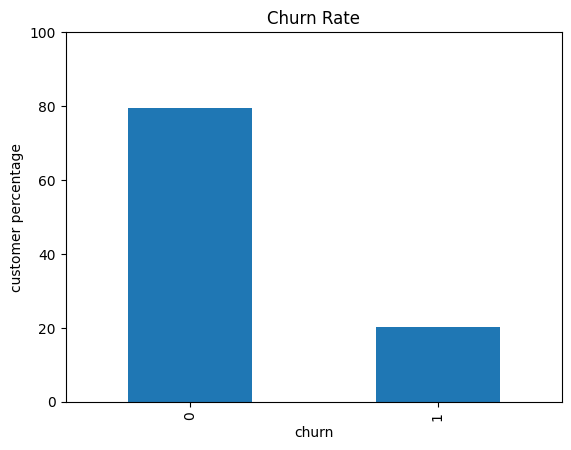

In [29]:
churn_rate.plot(kind='bar')
plt.title("Churn Rate")
plt.ylabel("customer percentage")
plt.ylim(0,100)

In [31]:
# creating new column age group 
age_bins = [18,25,35,45,55,65,100]
age_labels = ["18-25","26-35","36-45","46-55","56-65","66+"]
df['age_group'] = pd.cut(df['age'], bins=age_bins, labels=age_labels)
df[['age', 'age_group']].head()

,age,age_group
0,42,36-45
1,41,36-45
2,42,36-45
3,39,36-45
4,43,36-45


In [77]:
df['age_group'].value_counts().sort_index()

age_group
18-25     589
26-35    3542
36-45    3736
46-55    1311
56-65     536
66+       264
Name: count, dtype: int64

In [78]:
df[df['churn'] == 1]['age_group'].value_counts().sort_index()

age_group
18-25     44
26-35    301
36-45    733
46-55    663
56-65    259
66+       35
Name: count, dtype: int64

In [58]:
churned = df[df['churn']==1]
age_group_count = (churned['age_group'].value_counts(normalize=True) * 100).round(2)
age_group_churn_rate = (df.groupby('age_group', observed=False)['churn'].mean() * 100).round(2)
age_group_churn_rate

age_group
18-25     7.47
26-35     8.50
36-45    19.62
46-55    50.57
56-65    48.32
66+      13.26
Name: churn, dtype: float64

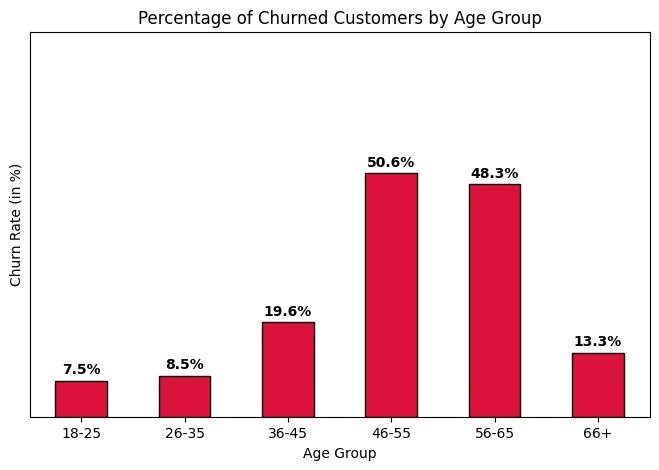

In [60]:
ax = age_group_churn_rate.plot(kind='bar', color='crimson', edgecolor='black', figsize=(8, 5))


ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=3, fontweight='bold')

plt.ylim(0, 80)
plt.yticks([])
plt.ylabel('Churn Rate (in %)')
plt.xlabel('Age Group')
plt.title('Percentage of Churned Customers by Age Group')

plt.xticks(rotation=0)

plt.show()

In [62]:
product_count = (churned['products_number'].value_counts(normalize=True) * 100).round(2)
product_churn_rate = (df.groupby('products_number',observed=False)['churn'].mean()*100).round(2)
product_churn_rate

products_number
1     27.71
2      7.58
3     82.71
4    100.00
Name: churn, dtype: float64

In [ ]:
product_churn_rate = (df.groupby('products_number',observed=False)['churn'].mean()*100).round(2)


In [75]:
df['products_number'].value_counts().sort_index()

products_number
1    5084
2    4590
3     266
4      60
Name: count, dtype: int64

In [76]:
df[df['churn'] == 1]['products_number'].value_counts().sort_index()

products_number
1    1409
2     348
3     220
4      60
Name: count, dtype: int64

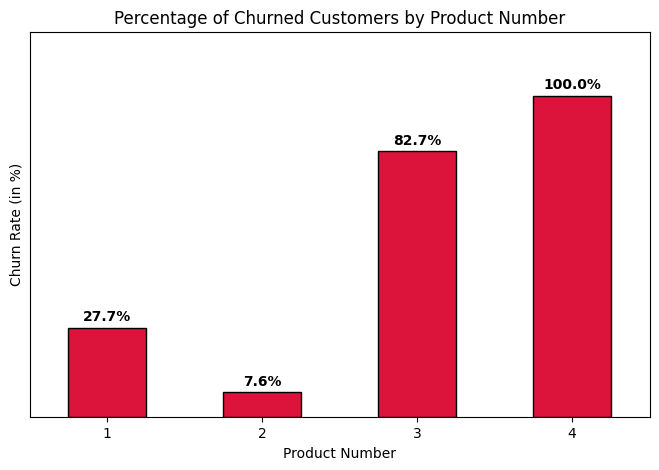

In [64]:
ax = product_churn_rate.plot(kind='bar', color='crimson', edgecolor='black', figsize=(8, 5))


ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=3, fontweight='bold')

plt.ylim(0, 120)
plt.yticks([])
plt.ylabel('Churn Rate (in %)')
plt.xlabel('Product Number')
plt.title('Percentage of Churned Customers by Product Number')

plt.xticks(rotation=0)

plt.show()

In [65]:
tenure_count = (churned['tenure'].value_counts(normalize=True) * 100).round(2)
tenure_churn_rate = (df.groupby('tenure',observed=False)['churn'].mean()*100).round(2)
tenure_churn_rate

tenure
0     23.00
1     22.42
2     19.18
3     21.11
4     20.53
5     20.65
6     20.27
7     17.22
8     19.22
9     21.65
10    20.61
Name: churn, dtype: float64

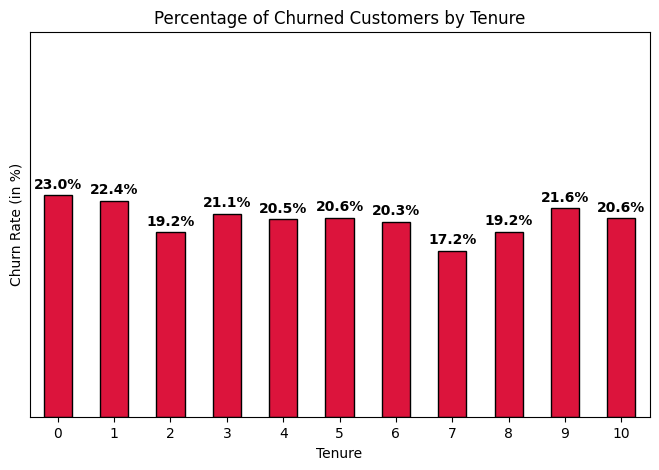

In [67]:
ax = tenure_churn_rate.plot(kind='bar', color='crimson', edgecolor='black', figsize=(8, 5))


ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=3, fontweight='bold')

plt.ylim(0, 40)
plt.yticks([])
plt.ylabel('Churn Rate (in %)')
plt.xlabel('Tenure')
plt.title('Percentage of Churned Customers by Tenure')

plt.xticks(rotation=0)

plt.show()

In [68]:
active_member_count = (churned['active_member'].value_counts(normalize=True) * 100).round(2)
active_member_churn_rate = (df.groupby('active_member',observed=False)['churn'].mean()*100).round(2)
active_member_churn_rate

active_member
0    26.85
1    14.27
Name: churn, dtype: float64

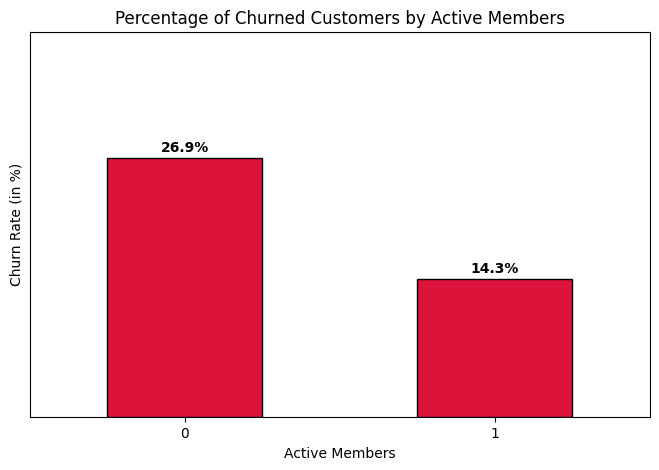

In [69]:
ax = active_member_churn_rate.plot(kind='bar', color='crimson', edgecolor='black', figsize=(8, 5))


ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=3, fontweight='bold')

plt.ylim(0, 40)
plt.yticks([])
plt.ylabel('Churn Rate (in %)')
plt.xlabel('Active Members')
plt.title('Percentage of Churned Customers by Active Members')

plt.xticks(rotation=0)

plt.show()

In [70]:
country_churn_rate = (churned['country'].value_counts(normalize=True) * 100).round(2)
country_churn_rate = (df.groupby('country',observed=False)['churn'].mean()*100).round(2)
country_churn_rate

country
France     16.15
Germany    32.44
Spain      16.67
Name: churn, dtype: float64

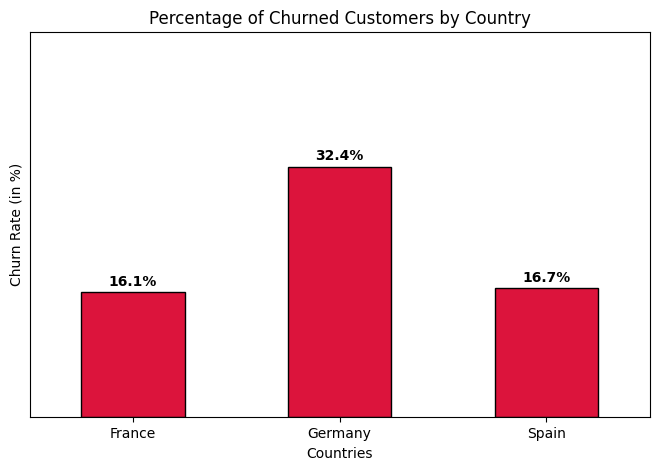

In [71]:
ax = country_churn_rate.plot(kind='bar', color='crimson', edgecolor='black', figsize=(8, 5))


ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=3, fontweight='bold')

plt.ylim(0, 50)
plt.yticks([])
plt.ylabel('Churn Rate (in %)')
plt.xlabel('Countries')
plt.title('Percentage of Churned Customers by Country')

plt.xticks(rotation=0)

plt.show()

In [79]:
gender_churn_rate = (df.groupby('gender', observed=False)['churn'].mean() * 100).round(2)
gender_churn_rate

gender
Female    25.07
Male      16.46
Name: churn, dtype: float64

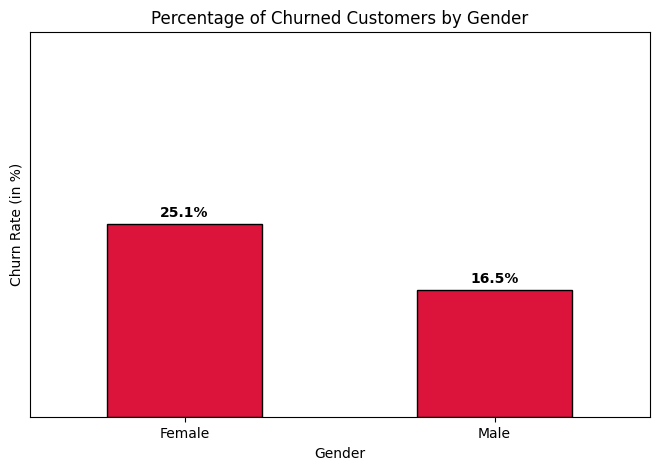

In [80]:
ax = gender_churn_rate.plot(kind='bar', color='crimson', edgecolor='black', figsize=(8, 5))


ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=3, fontweight='bold')

plt.ylim(0, 50)
plt.yticks([])
plt.ylabel('Churn Rate (in %)')
plt.xlabel('Gender')
plt.title('Percentage of Churned Customers by Gender')

plt.xticks(rotation=0)

plt.show()

In [81]:
credit_card_churn_rate = (df.groupby('credit_card', observed=False)['churn'].mean() * 100).round(2)
credit_card_churn_rate

credit_card
0    20.81
1    20.18
Name: churn, dtype: float64

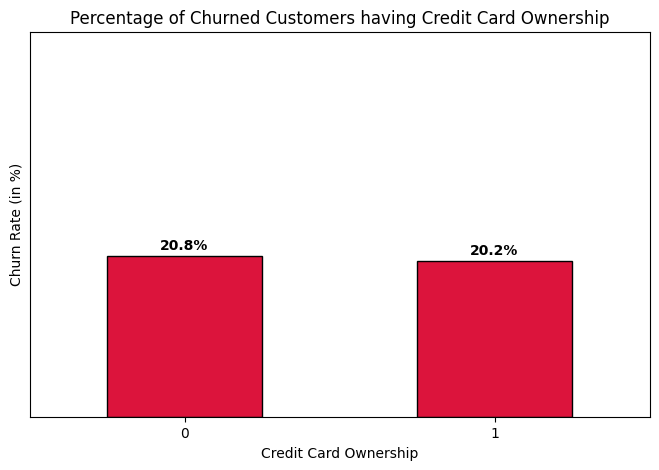

In [82]:
ax = credit_card_churn_rate.plot(kind='bar', color='crimson', edgecolor='black', figsize=(8, 5))


ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=3, fontweight='bold')

plt.ylim(0, 50)
plt.yticks([])
plt.ylabel('Churn Rate (in %)')
plt.xlabel('Credit Card Ownership')
plt.title('Percentage of Churned Customers having Credit Card Ownership')

plt.xticks(rotation=0)

plt.show()

In [94]:
# What is churn rate
churned_customer = df[df['churn']==1]
churned_customer_count = len(churned_customer)
total_customer_count = len(df)

In [103]:
churn_rate = round((churned_customer_count / total_customer_count)*100,2)
print(f"churned rate : {churn_rate}%")

churned rate : 20.37%


In [108]:
#What is churned balance 
churned_balance = sum(churned_customer['balance'])
print(f"Churned Balance : ${churned_balance}")

Churned Balance : $185588094.63


## 20.37% of customers churned, representing $185.58M of customer balance.

In [114]:
churned_by_age = churned_customer.groupby('age_group',observed=False)['balance'].sum()
churned_by_age

age_group
18-25     4383045.47
26-35    28086670.24
36-45    67377998.45
46-55    59323325.74
56-65    23216259.98
66+       3200794.75
Name: balance, dtype: float64

In [105]:
df.columns

Index(['customer_id', 'credit_score', 'country', 'gender', 'age', 'tenure',
       'balance', 'products_number', 'credit_card', 'active_member',
       'estimated_salary', 'churn', 'age_group'],
      dtype='object')

In [112]:
churn_balance_percent = round((churned_balance/total_balance)*100,2)
churn_balance_percent

24.26

In [116]:
age_summary = df.groupby('age_group', observed=False).agg(
    total_customers=('churn', 'count'),          # Total customer count per group
    churned_count=('churn', 'sum'),              # Number of churned customers (sum of 1s)
    total_lost_balance=('balance', lambda x: x[df.loc[x.index, 'churn'] == 1].sum()), # Sum balance ONLY for churned
    churn_rate=('churn', lambda x: (x.mean() * 100).round(2)) # True churn rate percentage
)
age_summary

,total_customers,churned_count,total_lost_balance,churn_rate
age_group,,,,
18-25,589,44,4383045.47,7.47
26-35,3542,301,28086670.24,8.50
36-45,3736,733,67377998.45,19.62
46-55,1311,663,59323325.74,50.57
56-65,536,259,23216259.98,48.32
66+,264,35,3200794.75,13.26


In [117]:
country_summary = df.groupby('country', observed=False).agg(
    total_customers=('churn', 'count'),          # Total customer count per group
    churned_count=('churn', 'sum'),              # Number of churned customers (sum of 1s)
    total_lost_balance=('balance', lambda x: x[df.loc[x.index, 'churn'] == 1].sum()), # Sum balance ONLY for churned
    churn_rate=('churn', lambda x: (x.mean() * 100).round(2)) # True churn rate percentage
)
country_summary

,total_customers,churned_count,total_lost_balance,churn_rate
country,,,,
France,5014,810,57666164.54,16.15
Germany,2509,814,97973915.53,32.44
Spain,2477,413,29948014.56,16.67


In [119]:
from sqlalchemy import create_engine
#connect to postgres 
username = 'postgres'
host='localhost'
password='Adnan123'
port = '5432'
database = 'customer_churn_analysis'

engine = create_engine(f"postgresql+psycopg2://{username}:{password}@{host}:{port}/{database}")

# load Dataframe into postgres
table = 'customer'
df.to_sql(table,engine,if_exists='replace',index=False)
print("Data loaded Successfully")

Data loaded Successfully


# Key Business Insights

### 1. Customer attrition is significant

The bank has a customer churn rate of 20.37%, indicating that approximately one in five customers have exited.

### 2. Churn represents a meaningful financial exposure

Churned customers account for approximately $185.58M in customer balance, representing 24.26% of the total balance in the dataset. This indicates that churn has potential financial significance beyond the number of customers lost.

### 3. Customer engagement appears to be an important churn signal

Inactive customers have a churn rate of 26.85%, compared with 14.27% among active customers. This suggests that customer engagement should be monitored as part of retention efforts.

### 4. Churn is concentrated among older customers

Customers aged 46–55 and 56–65 show substantially higher churn rates than younger age groups, with rates of 50.57% and 48.32%, respectively.

### 5. Germany requires further investigation

Germany has a churn rate of 32.44%, considerably higher than France and Spain. The retention team should investigate whether differences in customer engagement, product usage, or customer demographics explain this gap.

### 6. Credit-card ownership does not appear to be a major churn indicator

Churn rates are similar for customers with and without a credit card, suggesting that credit-card ownership alone may not be useful for identifying churn risk.

## Initial Retention Focus
Based on the exploratory analysis, the bank should prioritize investigation of:
#### Older customers, inactive customers, and customers in Germany, particularly where these characteristics overlap with high customer balances or limited product relationships.